<a href="https://colab.research.google.com/github/Abdoulaye279/Financial-Engineering/blob/main/var-es-sp500/09_costs_and_var.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 09 - Transaction costs, and the VaR of the risk-parity portfolios

Two things left out of 08:
1. costs. Until now the portfolios went back to their target weights every day for free. Here they drift with prices and are rebalanced on the first trading day of each month, paying 0 to 20 bp per unit traded.
2. the VaR of these portfolios. Their weights change every month, so for each month the last 1000 days are rebuilt with that month's weights and all the models of 02 are refitted on that history (`backtest_weights`).

Same seven assets as 07-08. Takes ~3 min.

In [1]:
# colab: get the repo first
try:
    import google.colab
    !git clone -q https://github.com/Abdoulaye279/Financial-Engineering
    %cd Financial-Engineering/var-es-sp500
except ImportError:
    pass

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from risk import *
plt.style.use("quant.mplstyle")

assets = ["spx", "aapl", "msft", "jpm", "xom", "gld", "tlt"]
prices = pd.concat({a: load_close("../black-scholes-sp500/data/sp500.csv" if a == "spx" else f"data/{a}.csv") for a in assets},
                   axis=1).dropna()
rets = np.log(prices).diff().dropna()
simple = np.exp(rets) - 1

W = {"1/7": pd.DataFrame(1 / 7, index=simple.index, columns=assets),
     "yearly ES": rolling_equal_risk_weights(simple),
     "monthly sample": monthly_risk_parity(rets, "sample"),
     "monthly DCC": monthly_risk_parity(rets, "dcc")}
start = max(w.dropna().index[0] for w in W.values())
print("from", start.date())

from 2009-01-02


In [3]:
rows = []
for nm, w in W.items():
    for cost in [0, 0.0005, 0.001, 0.002]:
        net, turn = rebalanced_returns(simple, w.loc[start:], cost=cost)
        lp = np.log1p(net)
        years = (lp.index[-1] - lp.index[0]).days / 365.25
        rows.append({"portfolio": nm, "cost (bp)": int(cost * 1e4), "return": 252 * lp.mean(), "vol": np.sqrt(252) * lp.std(),
                     "ES": var_es_hist(lp.values)[1], "turnover/yr": turn.sum() / years, "2022": np.expm1(lp.loc["2022"].sum())})
costs = pd.DataFrame(rows).set_index(["portfolio", "cost (bp)"])
costs.style.format({"return": "{:.2%}", "vol": "{:.1%}", "ES": "{:.2%}", "turnover/yr": "{:.2f}", "2022": "{:.1%}"})

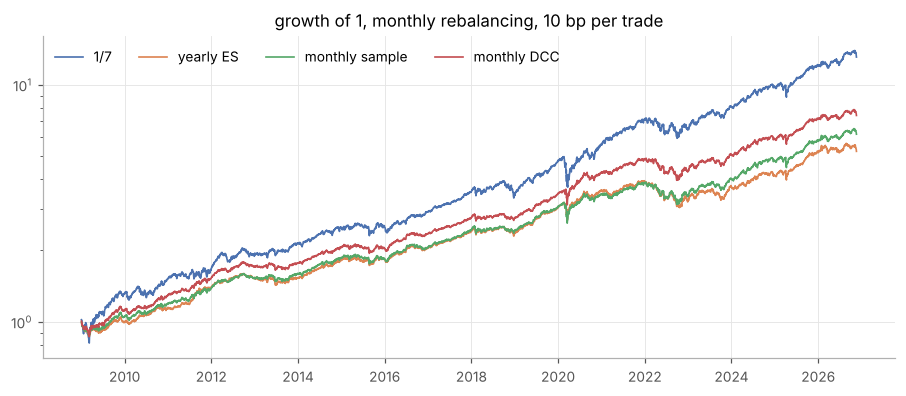

In [4]:
# with drift + monthly rebalancing every portfolio trades: ~0.45-0.55 of its value a year, DCC 1.66
# even at 20 bp DCC only loses 0.33% a year (11.4% -> 11.1%), it stays the best return of the three risk-parity ones
# at 5-10 bp, what real investors pay on these ETFs and large caps, the costs are basically noise
# the ranking between strategies doesn't change at any cost level
net = {nm: np.log1p(rebalanced_returns(simple, w.loc[start:], cost=0.001)[0]) for nm, w in W.items()}
fig, ax = plt.subplots(figsize=(10, 3.8))
for nm, lp in net.items():
    ax.plot(np.exp(lp.cumsum()), label=nm)
ax.set_yscale("log"); ax.set_title("growth of 1, monthly rebalancing, 10 bp per trade"); ax.legend(ncol=4)
plt.show()

In [5]:
# VaR backtest of the two out-of-sample risk-parity portfolios (gross returns, weights of each month)
names = {"normal": "normal", "hist": "historical", "garch": "garch", "gt": "garch student-t", "skt": "garch skewed-t",
         "gjrskt": "GJR skewed-t", "fhs": "FHS", "evt": "garch-EVT"}
full = lambda w: pd.concat([pd.DataFrame(np.nan, index=simple.index[simple.index < start], columns=assets), w.loc[start:]])
bts = {nm: backtest_weights(simple, full(W[nm])) for nm in ["yearly ES", "monthly DCC"]}
for nm, bt in bts.items():
    print(f"{nm}: {len(bt)} days, expected {round(0.01 * len(bt))} breaches")
    for m in names:
        breach = bt["ret"] < -bt[f"var_{m}"]
        ratio = (-bt["ret"][breach]).mean() / bt[f"es_{m}"][breach].mean()
        print(f"  {names[m]:16s} {breach.sum():3d} ({100*breach.mean():.2f}%)  kupiec p={kupiec(breach.values)[1]:.3f}  "
              f"christoffersen p={christoffersen(breach.values)[1]:.3f}  loss/ES={ratio:.2f}")
# none of them passes christoffersen (p <= 0.02 for every model, both portfolios): the breaches come in clusters
# yearly ES: also too many breaches for most models (1.3-1.9%). monthly DCC: the rate is fine (0.8-1.2%) for most
# and the ES is too small everywhere (loss/ES 1.04-1.31): these portfolios are riskier on bad days than their past says
# on the plain 1/7 portfolio (07) GJR skewed-t, FHS and EVT passed both tests, so it's the portfolio, not the models

yearly ES: 4499 days, expected 45 breaches
  normal            85 (1.89%)  kupiec p=0.000  christoffersen p=0.001  loss/ES=1.28
  historical        62 (1.38%)  kupiec p=0.016  christoffersen p=0.002  loss/ES=1.05
  garch             82 (1.82%)  kupiec p=0.000  christoffersen p=0.020  loss/ES=1.17
  garch student-t   68 (1.51%)  kupiec p=0.001  christoffersen p=0.004  loss/ES=1.10
  garch skewed-t    57 (1.27%)  kupiec p=0.084  christoffersen p=0.001  loss/ES=1.10
  GJR skewed-t      62 (1.38%)  kupiec p=0.016  christoffersen p=0.002  loss/ES=1.08
  FHS               62 (1.38%)  kupiec p=0.016  christoffersen p=0.002  loss/ES=1.07
  garch-EVT         59 (1.31%)  kupiec p=0.045  christoffersen p=0.001  loss/ES=1.07
monthly DCC: 4499 days, expected 45 breaches
  normal            51 (1.13%)  kupiec p=0.378  christoffersen p=0.000  loss/ES=1.31
  historical        35 (0.78%)  kupiec p=0.119  christoffersen p=0.000  loss/ES=1.04
  garch             71 (1.58%)  kupiec p=0.000  christoffersen

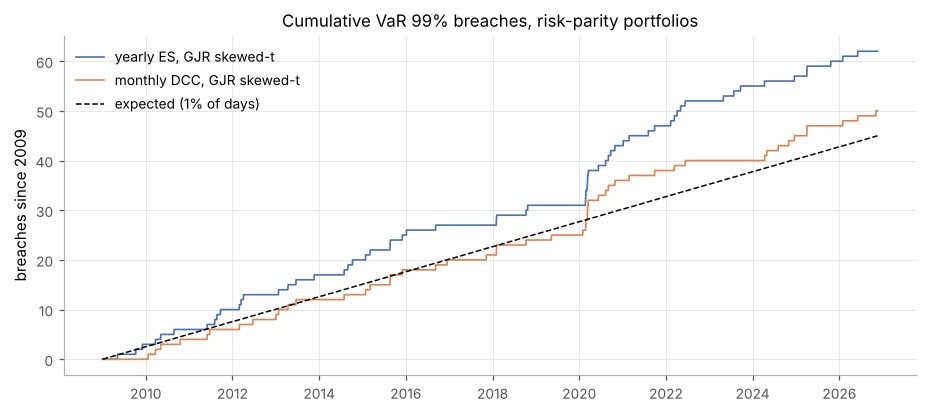

yearly ES    march 2020: 4 breaches  |  without march 2020: 1.30%  kupiec p=0.057  christoffersen p=0.007
monthly DCC  march 2020: 4 breaches  |  without march 2020: 1.03%  kupiec p=0.854  christoffersen p=0.012


In [6]:
fig, ax = plt.subplots(figsize=(10, 4))
for nm, bt in bts.items():
    ax.plot((bt["ret"] < -bt["var_gjrskt"]).cumsum(), label=f"{nm}, GJR skewed-t")
ax.plot(bts["monthly DCC"].index, 0.01 * np.arange(1, len(bts["monthly DCC"]) + 1), "k--", lw=1, label="expected (1% of days)")
ax.set_ylabel("breaches since 2009"); ax.set_title("Cumulative VaR 99% breaches, risk-parity portfolios"); ax.legend()
plt.show()
for nm, bt in bts.items():
    br = bt["ret"] < -bt["var_gjrskt"]
    rest = br[~((br.index.year == 2020) & (br.index.month == 3))]
    print(f"{nm:12s} march 2020: {br.loc['2020-03'].sum()} breaches  |  without march 2020: {100*rest.mean():.2f}%  "
          f"kupiec p={kupiec(rest.values)[1]:.3f}  christoffersen p={christoffersen(rest.values)[1]:.3f}")

In [7]:
print("daily returns (%), 9-18 march 2020:")
r = prices[["spx", "gld", "tlt"]].pct_change().loc["2020-03-09":"2020-03-18"]
print((100 * r).round(1).to_string())
print("cumulative:", (100 * ((1 + r).prod() - 1)).round(1).to_dict())
# 9-18 march 2020 ("dash for cash"): the S&P lost 19%, and gold (-11%) and long Treasuries (-13%) fell with it
# these portfolios hold ~50% in gold + bonds precisely because they usually rise on such days, and here they didn't
# 4 breaches that week for both portfolios. but march 2020 is not all of it: without it the DCC portfolio is at 1.03%,
# yet still clustered (p = 0.012): smaller groups in feb and sep 2020, and in 2022 for the yearly one (bonds again)
# -> a VaR fitted on the portfolio's own past counts on the hedges working. the risk is that they stop, all at once

daily returns (%), 9-18 march 2020:
             spx  gld  tlt
Date                      
2020-03-09  -7.6  0.2  2.7
2020-03-10   4.9 -2.1 -5.1
2020-03-11  -4.9 -0.4 -3.7
2020-03-12  -9.5 -4.0  0.6
2020-03-13   9.3 -3.1 -2.3
2020-03-16 -12.0 -1.1  6.5
2020-03-17   6.0  1.4 -6.7
2020-03-18  -5.2 -2.0 -5.6
cumulative: {'spx': -19.3, 'gld': -10.7, 'tlt': -13.4}
